In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import seaborn as sns
sns.set()
import torchvision
import torchvision.transforms as transforms
import umap

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.cluster import HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import rand_score
from sklearn.metrics import normalized_mutual_info_score

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
train = np.load("Z_train.npy")
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train)
transform = transforms.Compose([transforms.ToTensor()])
trainset = torchvision.datasets.KMNIST(
    root='./data', train=True, download=True, transform=transform)

##### KMeans

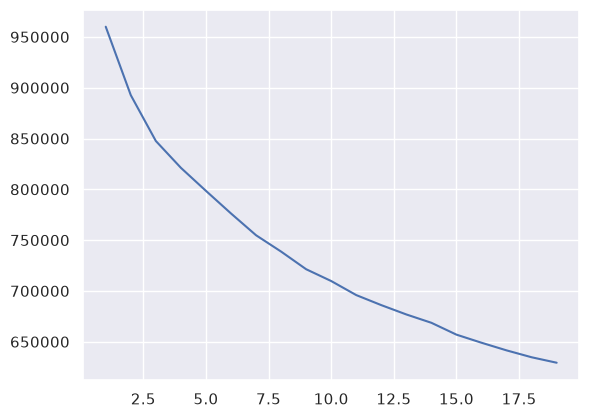

In [104]:
WCSS = []
for i in range(1,20):
    kmeans = KMeans(n_clusters=i,init="k-means++")
    kmeans.fit(train_scaled)
    WCSS.append(kmeans.inertia_)

plt.plot(range(1,20),WCSS)


Elbow method with a plain curve cant find no elbow
So the best approach to go about is to use Silhouette Score, Calinski Harabasz score and Davis Bouldin score to check what is the best number of cluster to consider in KMeans

In [4]:
y_true = trainset.targets.numpy()
pca  = PCA()
pca = PCA(n_components=0.80)
pca.fit(train_scaled)
scores_pca = pca.transform(train_scaled)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
for k in range(2, 16):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(u)
    print(k,
          round(silhouette_score(u, lab, sample_size=10000, random_state=42), 3),  # higher score is better
          round(calinski_harabasz_score(u, lab)),                                  # higher score is better
          round(davies_bouldin_score(u, lab), 3))                                  # lower score is better

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2 0.364 35520 1.247
3 0.363 34505 1.115
4 0.386 33152 1.033
5 0.422 37038 0.93
6 0.404 36092 1.063
7 0.443 37529 0.878
8 0.466 40174 0.846
9 0.498 44338 0.788
10 0.525 50954 0.71
11 0.507 53095 0.773
12 0.521 56190 0.749
13 0.503 54709 0.776
14 0.5 55030 0.822
15 0.482 54719 0.841


From this 10 is the desired number of clusters

In [5]:
y_true = trainset.targets.numpy()
pca  = PCA()
pca = PCA(n_components=0.80)
pca.fit(train_scaled)
scores_pca = pca.transform(train_scaled)
emb = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = KMeans(n_clusters=10, n_init=10, random_state=42).fit_predict(emb)
print("ARI: ", adjusted_rand_score(y_true, labels))
print("NMI: ", normalized_mutual_info_score(y_true, labels))

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


ARI:  0.4510849713623178
NMI:  0.5832193585935109


Silhouette Score:  0.06817959249019623
Adjusted Random Index:  0.20069037225018044
Random Index:  0.8552090029278265


/tmp/ipykernel_13831/322960358.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


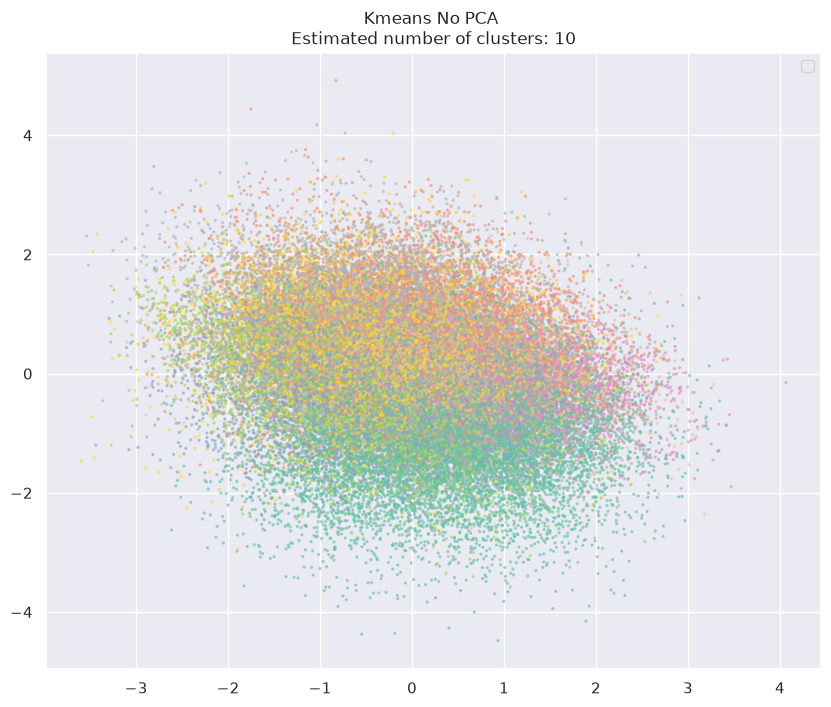

In [7]:
kmeans = KMeans(n_clusters=10,init="k-means++")
labels = kmeans.fit_predict(train_scaled)

x = train_scaled[:,0]
y = train_scaled[:,1]
plt.figure(figsize=(10,8))
plt.scatter(x,y,c=labels,cmap="Set2",s=2, alpha=0.5)
y_true = trainset.targets.numpy()
print("Silhouette Score: ", silhouette_score(train_scaled, labels))
print("Adjusted Random Index: ", adjusted_rand_score(y_true,labels))
print("Random Index: ", rand_score(y_true,labels))
plt.title(f"Kmeans No PCA \nEstimated number of clusters: 10")
plt.legend()
plt.show()

##### Kmeans with PCA

Components kept: 12
Variance explained: 0.84669447
Silhouette Score:  0.07809479534626007
Adjusted Random Index:  0.19238350922666164
Random Index:  0.8539067723350945


/tmp/ipykernel_13831/1769372696.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


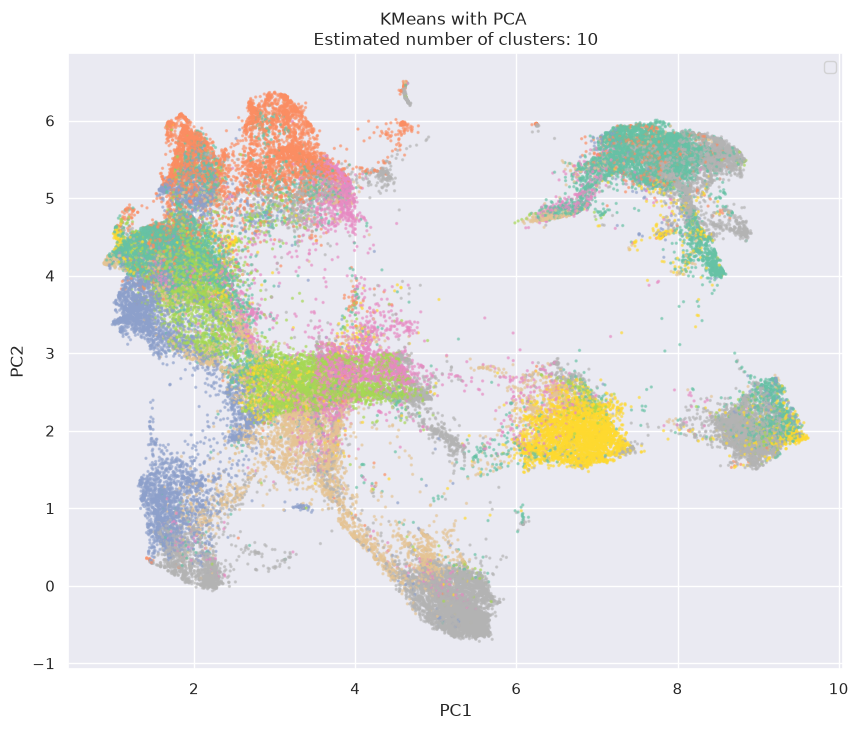

In [24]:
pca  = PCA()
pca = PCA(n_components=0.80)
pca.fit(train_scaled)
scores_pca = pca.transform(train_scaled)
print("Components kept:", pca.n_components_)
print("Variance explained:", pca.explained_variance_ratio_.sum())


kmeans = KMeans(n_clusters=10,init="k-means++",random_state=42)
labels = kmeans.fit_predict(scores_pca)

x = emb[:,0]
y = emb[:,1]
y_true = trainset.targets.numpy()
plt.figure(figsize=(10, 8))
plt.scatter(x, y, c=labels, cmap="Set2", s=2, alpha=0.5)
print("Silhouette Score: ", silhouette_score(scores_pca, labels))
print("Adjusted Random Index: ", adjusted_rand_score(y_true,labels))
print("Random Index: ", rand_score(y_true,labels))

plt.title("KMeans with PCA \nEstimated number of clusters: 10")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

KMeans with PCA & uMAP

Components kept: 12
Variance explained: 0.84669447


/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.45376476645469666
Adjusted Random Index:  0.4484772826459479
Random Index:  0.8938897814963582


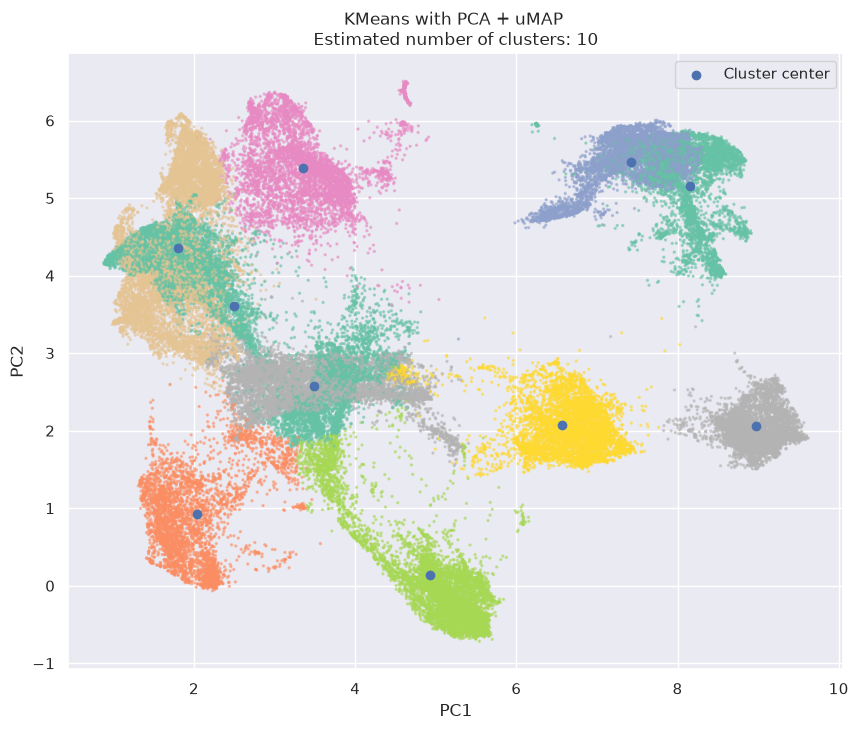

In [20]:
pca  = PCA()
pca = PCA(n_components=0.80)
pca.fit(train_scaled)
scores_pca = pca.transform(train_scaled)
print("Components kept:", pca.n_components_)
print("Variance explained:", pca.explained_variance_ratio_.sum())


kmeans = KMeans(n_clusters=10,init="k-means++",random_state=42)
emb = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = kmeans.fit_predict(emb)

x = emb[:,0]
y = emb[:,1]
y_true = trainset.targets.numpy()
plt.figure(figsize=(10, 8))
plt.scatter(x, y, c=labels, cmap="Set2", s=2, alpha=0.5)
print("Silhouette Score: ", silhouette_score(emb, labels))
print("Adjusted Random Index: ", adjusted_rand_score(y_true,labels))
print("Random Index: ", rand_score(y_true,labels))
center = kmeans.cluster_centers_
plt.scatter(center[:, 0], center[:, 1],label="Cluster center")

plt.title("KMeans with PCA + uMAP \nEstimated number of clusters: 10")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

#### DBSCAN

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


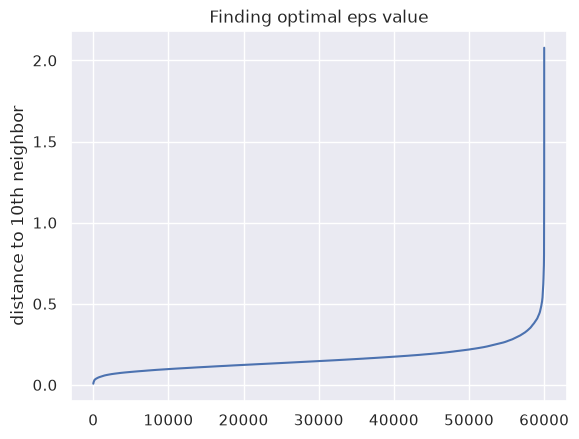

In [23]:
k = 10
pca = PCA(n_components=0.80)
scores_pca = pca.fit_transform(train_scaled)
emb = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
dist, _ = NearestNeighbors(n_neighbors=k).fit(emb).kneighbors(emb)
plt.plot(np.sort(dist[:, -1]))
plt.ylabel(f"distance to {k}th neighbor")
plt.title("Finding optimal eps value")
plt.show()

In [25]:
db = DBSCAN(eps=0.4,min_samples=10)
db = db.fit(train_scaled)
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 0
Estimated number of noise points: 60000


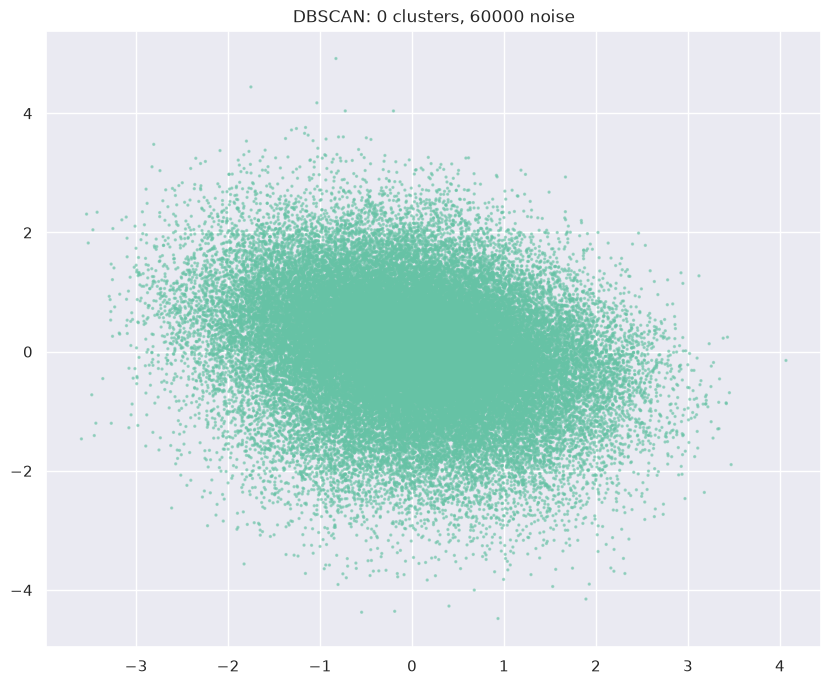

In [26]:
plt.figure(figsize=(10,8))
plt.scatter(train_scaled[:, 0], train_scaled[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"DBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Estimated number of clusters: 8
Estimated number of noise points: 311


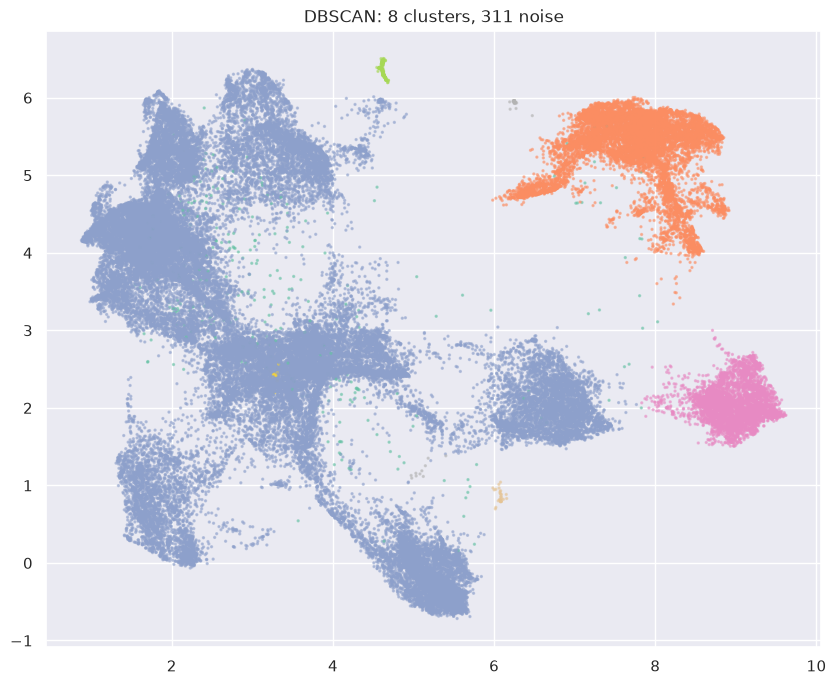

In [27]:
db = DBSCAN(eps=0.4,min_samples=10)
pca = PCA(n_components=0.80)
scores_pca = pca.fit_transform(train_scaled)
emb = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
db = db.fit(emb)
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)
plt.figure(figsize=(10,8))
plt.scatter(emb[:, 0], emb[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"DBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

#### HDBSCAN

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Estimated number of clusters: 0
Estimated number of noise points: 60000


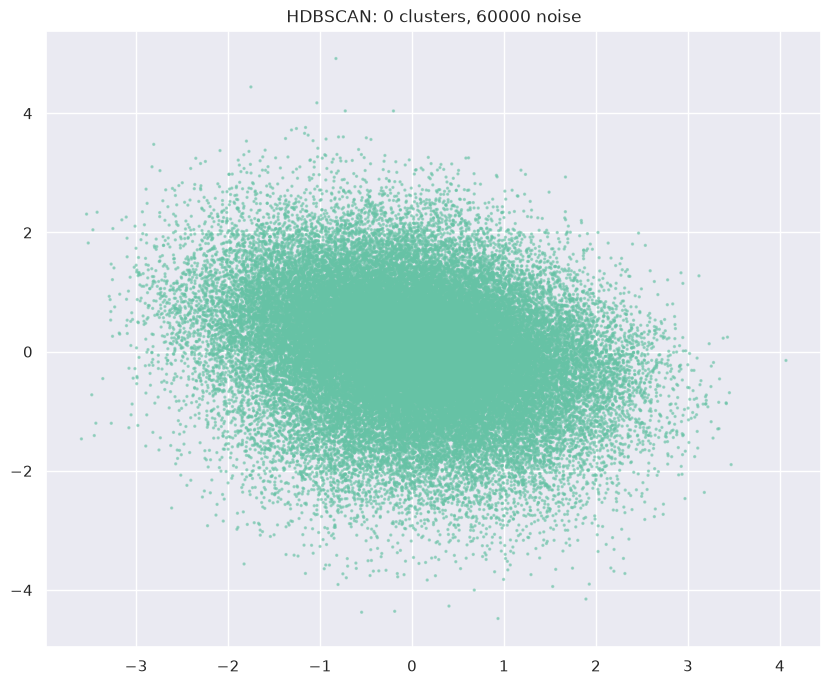

In [15]:
hdbscan = HDBSCAN(min_cluster_size=500, min_samples=50)
labels = hdbscan.fit_predict(train_scaled)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
plt.figure(figsize=(10, 8))
plt.scatter(train_scaled[:, 0], train_scaled[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"HDBSCAN: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

PCA + uMAP

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Estimated number of clusters: 13
Estimated number of noise points: 6538


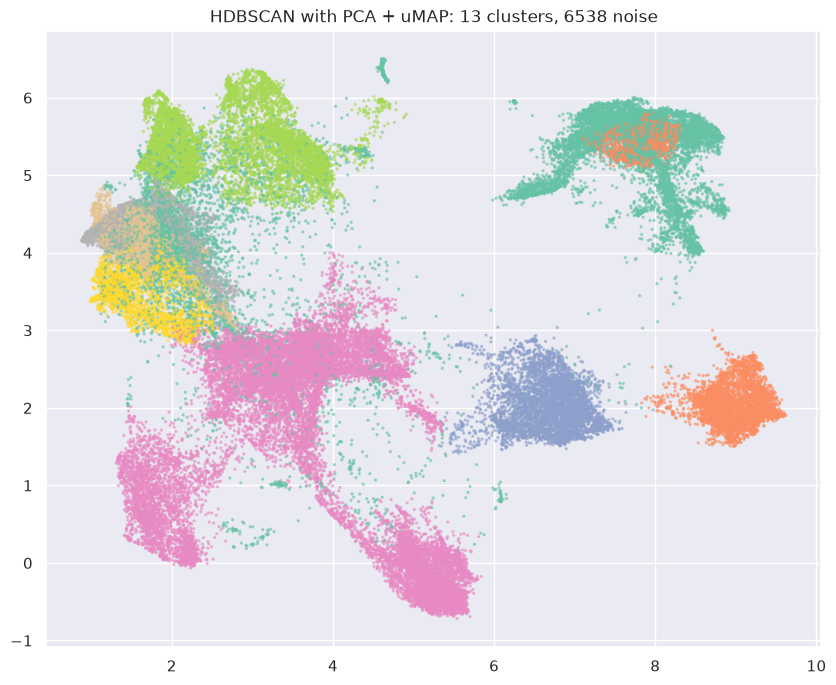

In [28]:
hdbscan = HDBSCAN(min_cluster_size=500, min_samples=50)
pca = PCA(n_components=0.80)
scores_pca = pca.fit_transform(train_scaled)
emb = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = hdbscan.fit_predict(emb)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
plt.figure(figsize=(10, 8))
plt.scatter(emb[:, 0], emb[:, 1], c=labels, cmap="Set2", s=2, alpha=0.5)
plt.title(f"HDBSCAN with PCA + uMAP: {n_clusters_} clusters, {n_noise_} noise")
plt.show()

PCA + tSNE